# Clustered Heatmap (with dendrograms)

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Scientific:* Specialised plots for statistics and scientific research: survival, effect sizes, agreement, omics, study flow and longitudinal data.

## Design purpose

A matrix heatmap whose rows and columns are reordered by hierarchical clustering, with dendrograms on the margins. Blocks of similar features and similar samples emerge without any prior grouping.

## When to use

- Show gene expression signatures across samples
- Group customers, products or sensors by similarity profiles
- Show a correlation matrix where variable order should reveal clusters

## Avoid when

- There are more than about 200 rows (summarise first or filter to the top-variance features)
- Rows must keep a meaningful fixed order (time, rank)

## Alternatives

- Plain heatmap
- PCA / UMAP scatter
- Parallel coordinates

## Design tips

- Z-score each row so color shows relative, not absolute, expression
- Use a diverging colormap centered on 0, and add a color strip for known sample groups

## Example

Synthetic expression of 40 genes in 16 samples (8 tumour, 8 normal) containing two co-regulated modules.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import seaborn as sns
from matplotlib.patches import Patch

### Data

In [2]:
rng = np.random.default_rng(3)
group = np.array(["Tumour"] * 8 + ["Normal"] * 8)
rng.shuffle(group)
expr = rng.normal(0, 1, (40, 16))
is_t = group == "Tumour"
expr[:12, is_t] += 2.2      # module up in tumour
expr[12:22, is_t] -= 1.8    # module down in tumour
expr[22:30] += np.linspace(-1, 1, 16)  # gradient module
genes = [f"G{i:02d}" for i in range(40)]
df = pd.DataFrame(expr + 8, index=genes, columns=[f"S{i:02d}" for i in range(16)])
group_palette = {"Tumour": PALETTE[1], "Normal": PALETTE[0]}
title = "Clustered expression heatmap"
df.iloc[:5, :6]

,S00,S01,S02,S03,S04,S05
G00,11.323000,8.225787,7.647369,9.918713,7.331954,9.144849
G01,8.540525,9.935088,7.730380,9.956441,9.002314,9.313540
G02,8.700545,7.555233,6.923594,10.226125,7.947253,11.605598
G03,5.506106,8.690125,8.491368,8.561143,8.061354,9.235900
G04,6.808773,8.354532,6.951594,11.605963,7.978349,9.827749


### Plot

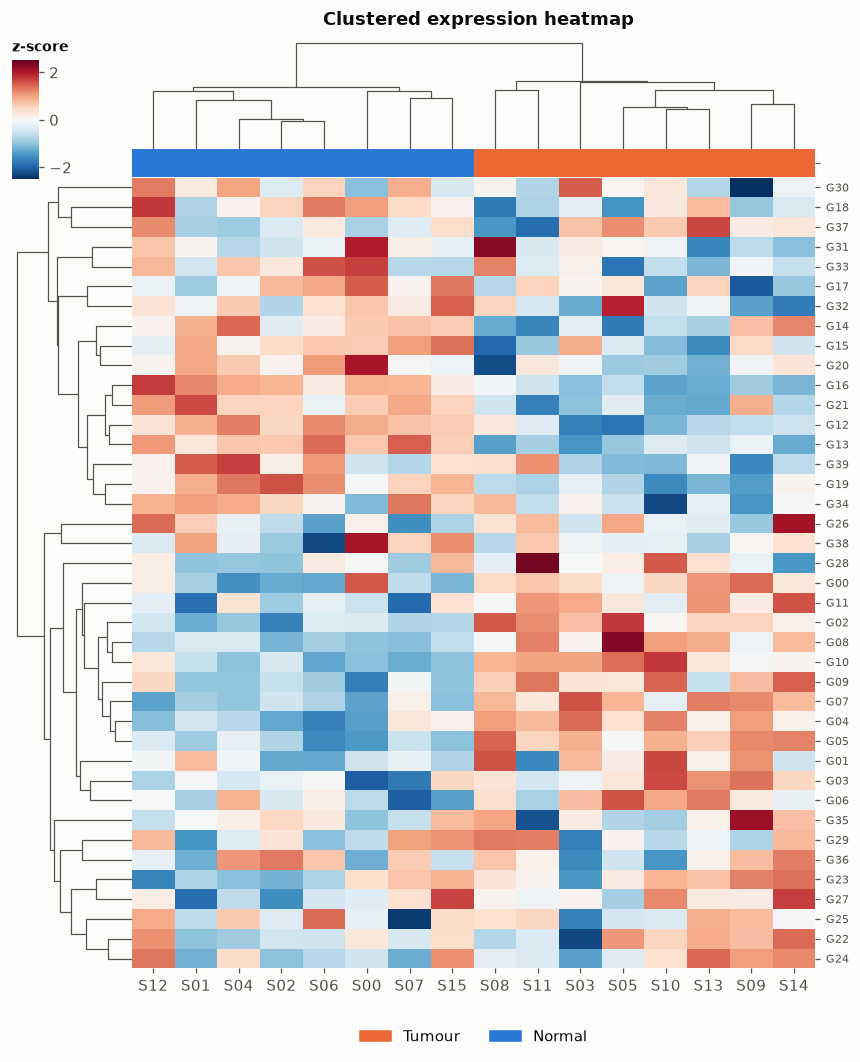

In [3]:
group_colors = pd.Series(group, index=df.columns).map(group_palette)
g = sns.clustermap(df, z_score=0, cmap=DIV_CMAP, center=0, vmin=-2.5, vmax=2.5, method="average",
                   metric="correlation", col_colors=group_colors, figsize=(8, 9),
                   dendrogram_ratio=(0.15, 0.12), cbar_pos=(0.02, 0.84, 0.03, 0.12),
                   yticklabels=True, tree_kws=dict(linewidths=0.8, colors="#52514e"))
g.ax_heatmap.tick_params(axis="y", labelsize=7)
g.ax_cbar.set_title("z-score", fontsize=9)
g.ax_heatmap.legend(handles=[Patch(color=c, label=k) for k, c in group_palette.items()],
                    loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2)
g.figure.suptitle(title, x=0.55, y=1.01, fontweight="bold")
fig = g.figure
plt.show()

## How to read it

Rows (genes) and columns (samples) are reordered so that similar ones sit together. Samples split cleanly into tumour and normal, driven by an up-regulated block (red) and a down-regulated block (blue).

## Try it with real data

**Source:** sklearn.datasets.load_breast_cancer() — 40 sampled tumours (20 malignant, 20 benign), 10 nucleus features, bundled with scikit-learn

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
from sklearn.datasets import load_breast_cancer
bc = load_breast_cancer(as_frame=True)
rng = np.random.default_rng(3)
target = bc.target.values
idx = np.r_[rng.choice(np.where(target == 0)[0], 20, replace=False),
            rng.choice(np.where(target == 1)[0], 20, replace=False)]
rng.shuffle(idx)
feats = [c for c in bc.feature_names if c.startswith("mean ")]      # 10 nucleus features
df = bc.data.loc[idx, feats].T
df.columns = [f"P{i:02d}" for i in range(len(idx))]
group = np.where(target[idx] == 0, "Malignant", "Benign")
group_palette = {"Malignant": PALETTE[1], "Benign": PALETTE[0]}
title = "Breast tumours clustered by nucleus features"
df.iloc[:5, :6]

,P00,P01,P02,P03,P04,P05
mean radius,10.9400,12.21000,11.0600,15.3400,22.2700,12.00000
mean texture,18.5900,18.02000,17.1200,14.2600,19.6700,15.65000
mean perimeter,70.3900,78.31000,71.2500,102.5000,152.8000,76.95000
mean area,370.0000,458.40000,366.5000,704.4000,1509.0000,443.30000
mean smoothness,0.1004,0.09231,0.1194,0.1073,0.1326,0.09723


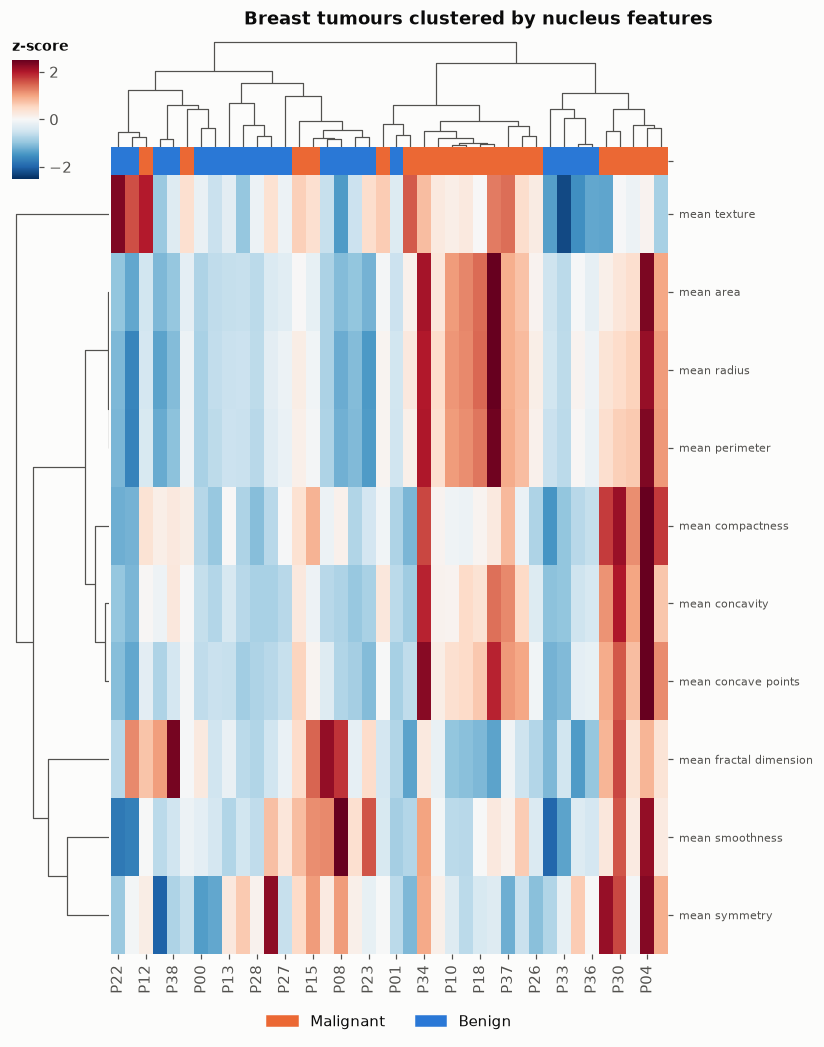

In [5]:
group_colors = pd.Series(group, index=df.columns).map(group_palette)
g = sns.clustermap(df, z_score=0, cmap=DIV_CMAP, center=0, vmin=-2.5, vmax=2.5, method="average",
                   metric="correlation", col_colors=group_colors, figsize=(8, 9),
                   dendrogram_ratio=(0.15, 0.12), cbar_pos=(0.02, 0.84, 0.03, 0.12),
                   yticklabels=True, tree_kws=dict(linewidths=0.8, colors="#52514e"))
g.ax_heatmap.tick_params(axis="y", labelsize=7)
g.ax_cbar.set_title("z-score", fontsize=9)
g.ax_heatmap.legend(handles=[Patch(color=c, label=k) for k, c in group_palette.items()],
                    loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=2)
g.figure.suptitle(title, x=0.55, y=1.01, fontweight="bold")
fig = g.figure
plt.show()

---
Standalone script: [`clustered_heatmap.py`](clustered_heatmap.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)